# POST-PHASE-13 H2-A-B2 — Downstream Regional Segmentation Analysis

## 1. Governance / Adaptive-Development Disclosure

This notebook is READ-ONLY. It contains no training, no localizer inference, and no segmentation inference.

H2A is an adaptive VAL-development revision undertaken after:
- Phase 13 `REVISE_LOCALIZER`
- H1 acceptance-only insufficiency

The H2A checkpoint-selection rule was frozen before H2A-B1 training.
The downstream protocol was frozen before H2A-B2 segmentation execution.

No H2A downstream result substitutes for final TEST evaluation.
TEST remains untouched.


In [1]:

import hashlib, json, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.figsize"] = (10, 5)

ROOT = Path(r"D:\Softfors\jup")
TABLES = ROOT / "reports" / "tables"
AUDITS = ROOT / "reports" / "audits"

def sha(p):
    p = Path(p)
    if not p.is_absolute():
        p = ROOT / p
    return hashlib.sha256(p.read_bytes()).hexdigest()

print("Environment OK")


Environment OK


## 2. H2A Scientific Question

> Does the H2A deployment-balanced checkpoint selection improve the complete GT-free predicted-region segmentation path when EVERYTHING downstream is held fixed?

Authorized:
- frozen H2A epoch-83 proposals
- four frozen segmentation architectures
- frozen global cache
- frozen fusion semantics

Not authorized (and not performed):
- localizer training / forward / proposal regeneration
- H1 filtering
- threshold search / proposal grid
- segmentation checkpoint change
- loss / target / architecture redesign


## 3. B1 Identity and Best Epoch 83

H2A-B1 training evaluation artifact:
`reports/audits/post_phase13_h2a_training_evaluation.json`


In [2]:

ev = json.loads((AUDITS / "post_phase13_h2a_training_evaluation.json").read_text("utf-8"))
print(f"status: {ev['status']}")
print(f"best_epoch: {ev['best_epoch']}")
print(f"completed_epochs: {ev['completed_epochs']}")
print(f"termination: {ev['termination']['reason']}")
print(f"best.pt SHA: {ev['checkpoint_shas']['best_pt']}")
print(f"best tuple: {ev['best_six_term_tuple']}")


status: PASS
best_epoch: 83
completed_epochs: 98
termination: EARLY_STOPPING_PATIENCE
best.pt SHA: 2e2e8f7909649f50cf7b830aab357d9e14a4b62b71a00fc0efe22aa300ba54c8
best tuple: [0.4522162369629855, 0.6944444444444444, 0.6381578947368421, 0.27571115973741794, -0.0047946270615735415, -1.8425761369558482]


## 4. B1 Integrity Evidence

- Trajectory reproduction: PASS (68 overlapping epochs, max abs val_loss diff 0.0)
- Selection replay: PASS (0 mismatches)
- Checkpoint cross-check limitation: disclosed (epochs 31/53/68 not retained)


In [3]:

traj = json.loads((AUDITS / "post_phase13_h2a_training_trajectory_reproduction.json").read_text("utf-8"))
print(f"trajectory status: {traj['status']}")
print(f"overlapping epochs: {traj['comparison']['overlapping_epochs']}")
print(f"max abs train_loss diff: {traj['comparison']['max_abs_train_loss_diff']:.3e}")
print(f"max abs val_loss diff: {traj['comparison']['max_abs_val_loss_diff']:.3e}")

repl = json.loads((AUDITS / "post_phase13_h2a_selection_replay_verification.json").read_text("utf-8"))
print(f"selection replay status: {repl['status']}")
print(f"mismatch_count: {repl['mismatch_count']}")


trajectory status: PASS
overlapping epochs: 68
max abs train_loss diff: 4.441e-16
max abs val_loss diff: 0.000e+00
selection replay status: PASS
mismatch_count: 0


## 5. B1 Checkpoint-Crosscheck Limitation

The original H2A-B1 protocol requested model-tensor cross-checks at historical epochs 31 / 53 / 68.
The completed H2A run did NOT retain epoch-specific model snapshots at those epochs.

Therefore the model-tensor cross-check is **NOT_RECOVERABLE_FROM_RETAINED_H2A_CHECKPOINTS**.

The 68-epoch loss/LR trajectory reproduction provides strong empirical support that gradient-update semantics were unchanged. Direct model-tensor equality at epochs 31/53/68 was not available because H2A did not retain epoch-specific snapshots at those epochs.

Classification: NONBLOCKING_SECONDARY_INTEGRITY_CHECK_UNAVAILABLE


## 6. Frozen H2A Proposal Identity

The 457 proposals from H2A-B1 standalone evaluation are the authoritative downstream input.


In [4]:

prop = pd.read_csv(TABLES / "post_phase13_h2a_best_checkpoint_proposals.csv")
case = pd.read_csv(TABLES / "post_phase13_h2a_best_checkpoint_case_proposals.csv")
comp = pd.read_csv(TABLES / "post_phase13_h2a_best_checkpoint_component_coverage.csv")
print(f"proposals: {len(prop)} rows")
print(f"cases: {len(case)} rows")
print(f"components: {len(comp)} rows")
print(f"proposal config: threshold=0.10 margin=0.20 top_k=5 NMS=0.30")
for k, fname in (("case","post_phase13_h2a_best_checkpoint_case_proposals.csv"),
                       ("proposals","post_phase13_h2a_best_checkpoint_proposals.csv"),
                       ("component","post_phase13_h2a_best_checkpoint_component_coverage.csv"),
                       ("stratified","post_phase13_h2a_best_checkpoint_size_stratified.csv")):
    p = TABLES / fname
    print(f"  {k} SHA: {sha(p)[:16]}...")


proposals: 457 rows
cases: 103 rows
components: 152 rows
proposal config: threshold=0.10 margin=0.20 top_k=5 NMS=0.30
  case SHA: 93ebebf4ede237e4...
  proposals SHA: 4004e5b0b38bec11...
  component SHA: e93163b2b42eeadf...
  stratified SHA: 23435283ecdfb963...


## 7. Segmentation Checkpoint Bindings

Four frozen architectures loaded with strict state_dict matching (missing=0, unexpected=0).


In [5]:

checks = {
    "unet": (str(ROOT / "checkpoints/phase9_kub_unet_baseline_seed42_512_clean_v3/best.pt"),
             "7b955ba86464a2fec2d569ecb6124de1fa9a4e66d0b5d58b267be9a280b4c2c0"),
    "attention_unet": (str(ROOT / "checkpoints/phase10_kub_attention_unet_seed42_512_clean_v3/best.pt"),
                       "a49b19d66e43b57ed082ea6efc0ac10bccf444277abd3540dc68612bf30b88b3"),
    "unetpp": (str(ROOT / "checkpoints/phase10_kub_unetpp_seed42_512_clean_v3/best.pt"),
               "ec7eb13f32e43af27eab7fc617bd1a2a8fcce1d6651a1b4a3653f3e4d1283269"),
    "deeplabv3plus": (str(ROOT / "checkpoints/phase10_kub_deeplabv3plus_seed42_512_clean_v3/best.pt"),
                      "f519027ba1a3a4d6212d83fecd4379f61f71bc05b0751924b9660da08d597dad"),
}
for name, (path, expected) in checks.items():
    actual = sha(path)
    match = actual == expected
    print(f"  {name:<16} {'PASS' if match else 'FAIL'}  {actual[:16]}...")


  unet             PASS  7b955ba86464a2fe...
  attention_unet   PASS  a49b19d66e43b57e...
  unetpp           PASS  ec7eb13f32e43af2...
  deeplabv3plus    PASS  f519027ba1a3a4d6...


## 8. Global Cache Reproduction

Reused the frozen Phase13 Part1D-B FLOAT32 global cache.
Manifest: 412 items = 103 cases x 4 models.


In [6]:

man = pd.read_csv(ROOT / "data_cache/phase13_part1d_b_predicted_region_clean_v3/global_512_manifest.csv")
print(f"manifest items: {len(man)}")
print(f"models: {sorted(man.model.unique())}")
print(f"dtype: {man['dtype'].unique().tolist()}")
print(f"manifest SHA: {sha('data_cache/phase13_part1d_b_predicted_region_clean_v3/global_512_manifest.csv')[:16]}...")
print(f"expected SHA: 76e1034d2bc7925260af33826fc19565b2d5ef786c612a7ad71f3bde46fb89a8")


manifest items: 412
models: ['attention_unet', 'deeplabv3plus', 'unet', 'unetpp']
dtype: ['float32']
manifest SHA: 76e1034d2bc79252...
expected SHA: 76e1034d2bc7925260af33826fc19565b2d5ef786c612a7ad71f3bde46fb89a8


## 9. Regional Crop / Restore Semantics

Frozen Part1D helper (`phase13_part1d_predicted_region_inference.py`) SHA:
`8cd7e39814a049a025f706c57ccea0b535a230908a177690d6289318234c6284`

- Native proposal rectangle already includes margin 0.20 (not applied twice)
- Input: valid native region -> zero-pad to square -> resize to 512 bilinear -> [0,1]
- Restore: regional prob 512 -> full square bilinear -> strip padding -> native coords


## 10. Fusion Semantics

- U_H2A = union of clipped frozen H2A proposal rectangles
- Regional overlaps: MAX among regional probability maps only
- Final P(x) = R(x) inside U_H2A, G(x) outside U_H2A
- NEVER max(G,R) inside the proposal union
- Zero proposals -> P == G exactly
- Threshold: 0.5 after complete fusion


## 11. Localizer Epoch 53 -> Epoch 83 Comparison


In [7]:

loc = pd.read_csv(TABLES / "post_phase13_h2a_vs_phase13_localizer_comparison.csv")
print(loc.to_string(index=False))


                        quantity  phase13_best_epoch53  h2a_best_epoch83  delta_h2a_minus_phase13
            proposal_total_count            494.000000        457.000000               -37.000000
proposal_pixel_any_hit_precision              0.246964          0.275711                 0.028748
 proposal_bbox_any_hit_precision              0.248988          0.273523                 0.024535
                   tiny_recall90              0.680556          0.694444                 0.013889
                overall_recall90              0.598684          0.638158                 0.039474
                overall_recall50              0.789474          0.822368                 0.032895
              any_overlap_recall              0.848684          0.875000                 0.026316
                   mean_coverage              0.758402          0.787897                 0.029495
        mean_proposal_union_area              0.004846          0.004795                -0.000051
              propos

## 12. Model-Level Downstream Summary


In [8]:

sum_df = pd.read_csv(TABLES / "post_phase13_h2a_downstream_model_summary.csv")
print(sum_df.to_string(index=False))


         model   model_display  proposal_count  mean_proposals_per_image  mean_intervention_union_area  global_macro_dice  phase13_predicted_macro_dice  h2a_predicted_macro_dice  oracle_macro_dice  DELTA_H2A_GLOBAL_DICE  DELTA_H2A_PHASE13_DICE  ORACLE_GAIN_FROM_GLOBAL  H2A_ORACLE_BENEFIT_RETENTION  H2A_ORACLE_GAP  global_macro_iou  phase13_predicted_macro_iou  h2a_predicted_macro_iou  oracle_macro_iou  global_macro_precision  phase13_predicted_macro_precision  h2a_predicted_macro_precision  oracle_macro_precision  global_macro_recall  phase13_predicted_macro_recall  h2a_predicted_macro_recall  oracle_macro_recall  mean_global_fp  mean_phase13_fp  mean_h2a_fp  mean_oracle_fp  mean_global_fn  mean_phase13_fn  mean_h2a_fn  mean_oracle_fn  fp_delta_vs_global  fp_delta_vs_phase13  fn_delta_vs_global  fn_delta_vs_phase13  cases_improved_vs_global  cases_same_vs_global  cases_worse_vs_global  cases_improved_vs_phase13  cases_same_vs_phase13  cases_worse_vs_phase13  component_recoveries_vs_glo

## 13. GLOBAL vs H2A

H2A predicted-region path compared against the frozen GLOBAL comparator.


In [9]:

sum_df = pd.read_csv(TABLES / "post_phase13_h2a_downstream_model_summary.csv")
_cols = ["model_display", "global_macro_dice", "h2a_predicted_macro_dice",
         "DELTA_H2A_GLOBAL_DICE", "global_macro_precision", "h2a_predicted_macro_precision",
         "global_macro_recall", "h2a_predicted_macro_recall",
         "mean_global_fp", "mean_h2a_fp", "mean_global_fn", "mean_h2a_fn",
         "cases_improved_vs_global", "cases_same_vs_global", "cases_worse_vs_global"]
print(sum_df[_cols].to_string(index=False))


  model_display  global_macro_dice  h2a_predicted_macro_dice  DELTA_H2A_GLOBAL_DICE  global_macro_precision  h2a_predicted_macro_precision  global_macro_recall  h2a_predicted_macro_recall  mean_global_fp  mean_h2a_fp  mean_global_fn  mean_h2a_fn  cases_improved_vs_global  cases_same_vs_global  cases_worse_vs_global
           UNet           0.594180                  0.313779              -0.280400                0.693919                       0.245046             0.653931                    0.686679     1297.252427  8344.252427     2561.621359  2381.330097                        11                     0                     92
Attention U-Net           0.629805                  0.320173              -0.309632                0.670962                       0.253042             0.701770                    0.704895     1377.194175  8683.320388     2428.135922  2441.300971                         8                     1                     94
         UNet++           0.640516               

## 14. Phase13 Predicted vs H2A

H2A predicted-region path compared against the frozen Phase13 epoch-53
predicted-region comparator (`PREDICTED_REGION_FLOAT_GLOBAL_RETAINED`).


In [10]:

_cols = ["model_display", "phase13_predicted_macro_dice", "h2a_predicted_macro_dice",
         "DELTA_H2A_PHASE13_DICE", "phase13_predicted_macro_precision", "h2a_predicted_macro_precision",
         "phase13_predicted_macro_recall", "h2a_predicted_macro_recall",
         "mean_phase13_fp", "mean_h2a_fp", "mean_phase13_fn", "mean_h2a_fn",
         "cases_improved_vs_phase13", "cases_same_vs_phase13", "cases_worse_vs_phase13"]
print(sum_df[_cols].to_string(index=False))


  model_display  phase13_predicted_macro_dice  h2a_predicted_macro_dice  DELTA_H2A_PHASE13_DICE  phase13_predicted_macro_precision  h2a_predicted_macro_precision  phase13_predicted_macro_recall  h2a_predicted_macro_recall  mean_phase13_fp  mean_h2a_fp  mean_phase13_fn  mean_h2a_fn  cases_improved_vs_phase13  cases_same_vs_phase13  cases_worse_vs_phase13
           UNet                      0.302314                  0.313779                0.011466                           0.234969                       0.245046                        0.672113                    0.686679      8622.223301  8344.252427      2484.932039  2381.330097                         50                      3                      50
Attention U-Net                      0.308619                  0.320173                0.011554                           0.243961                       0.253042                        0.688298                    0.704895      8905.262136  8683.320388      2546.961165  2441.300971       

## 15. ORACLE vs H2A

H2A predicted-region path compared against the frozen Phase12 oracle comparator
(`ORACLE_FLOAT_GLOBAL_RETAINED`, GT-derived localization). No comparator is a
winner or reference architecture.


In [11]:

_cols = ["model_display", "oracle_macro_dice", "h2a_predicted_macro_dice",
         "H2A_ORACLE_GAP", "ORACLE_GAIN_FROM_GLOBAL", "H2A_ORACLE_BENEFIT_RETENTION",
         "oracle_macro_precision", "h2a_predicted_macro_precision",
         "oracle_macro_recall", "h2a_predicted_macro_recall"]
print(sum_df[_cols].to_string(index=False))


  model_display  oracle_macro_dice  h2a_predicted_macro_dice  H2A_ORACLE_GAP  ORACLE_GAIN_FROM_GLOBAL  H2A_ORACLE_BENEFIT_RETENTION  oracle_macro_precision  h2a_predicted_macro_precision  oracle_macro_recall  h2a_predicted_macro_recall
           UNet           0.724722                  0.313779       -0.410942                 0.130542                     -2.147969                0.670271                       0.245046             0.859321                    0.686679
Attention U-Net           0.699595                  0.320173       -0.379422                 0.069790                     -4.436652                0.659250                       0.253042             0.836333                    0.704895
         UNet++           0.726679                  0.323046       -0.403633                 0.086164                     -3.684488                0.686081                       0.254114             0.856491                    0.698122
     DeepLabV3+           0.750372                  0.28

## 16. Dice / IoU
## 17. Precision / Recall
## 18. FP / FN


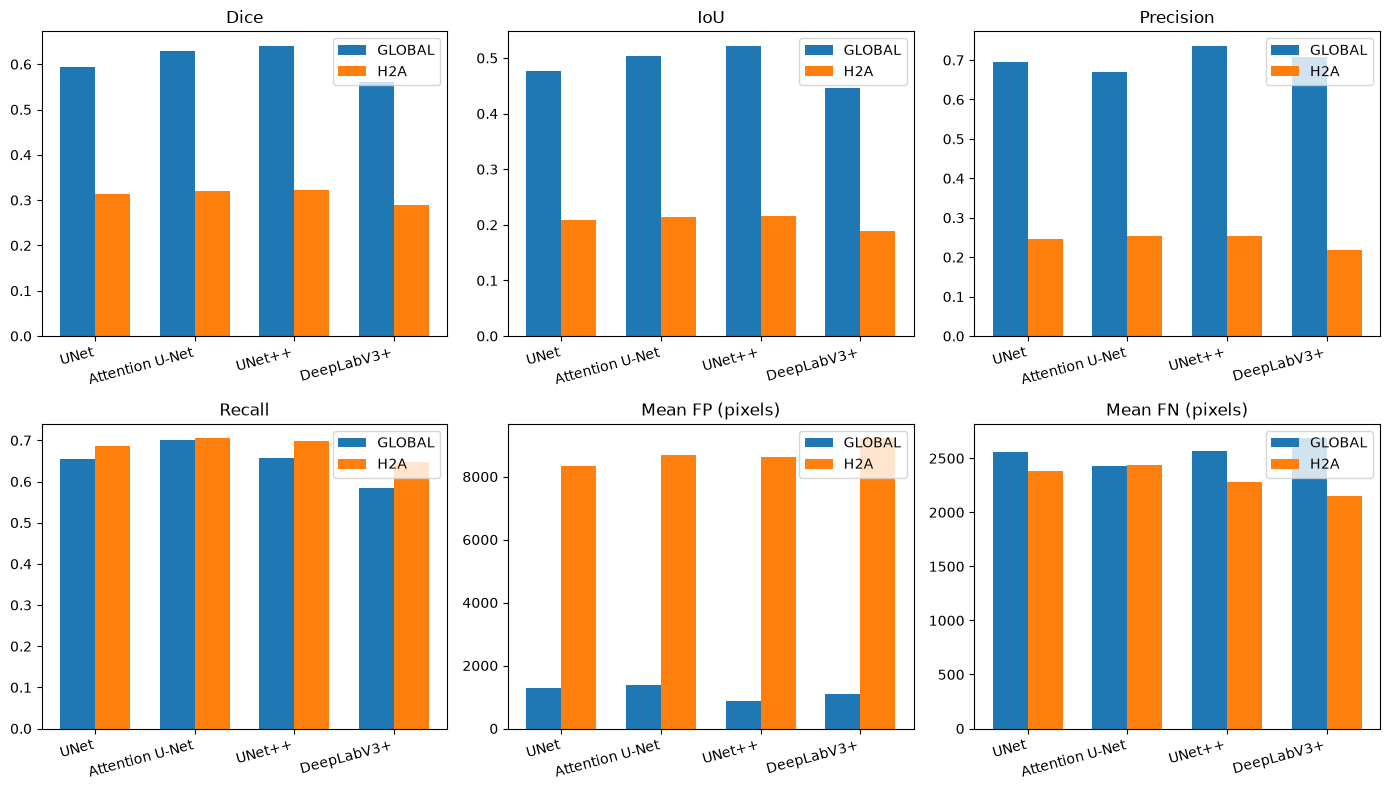

In [12]:

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

metrics = [
    ("global_macro_dice", "h2a_predicted_macro_dice", "Dice"),
    ("global_macro_iou", "h2a_predicted_macro_iou", "IoU"),
    ("global_macro_precision", "h2a_predicted_macro_precision", "Precision"),
    ("global_macro_recall", "h2a_predicted_macro_recall", "Recall"),
    ("mean_global_fp", "mean_h2a_fp", "Mean FP (pixels)"),
    ("mean_global_fn", "mean_h2a_fn", "Mean FN (pixels)"),
]

for ax, (gcol, hcol, title) in zip(axes.flat, metrics):
    x = np.arange(len(sum_df))
    width = 0.35
    ax.bar(x - width/2, sum_df[gcol], width, label="GLOBAL")
    ax.bar(x + width/2, sum_df[hcol], width, label="H2A")
    ax.set_xticks(x)
    ax.set_xticklabels(sum_df["model_display"], rotation=15, ha="right")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()


## 19. Component Recoveries / Losses


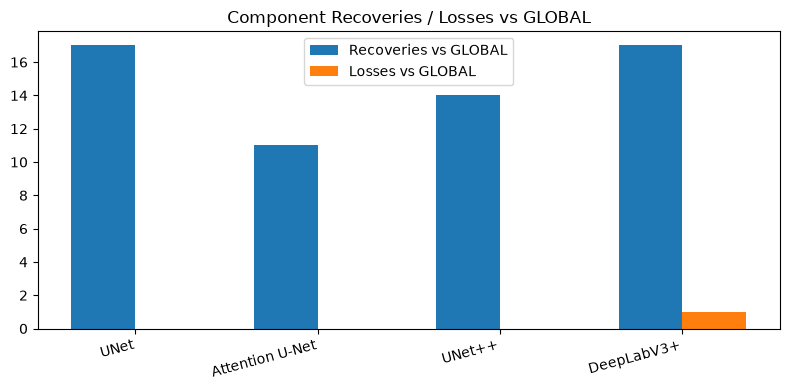

In [13]:

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(sum_df))
width = 0.35
ax.bar(x - width/2, sum_df["component_recoveries_vs_global"], width, label="Recoveries vs GLOBAL")
ax.bar(x + width/2, sum_df["component_losses_vs_global"], width, label="Losses vs GLOBAL")
ax.set_xticks(x)
ax.set_xticklabels(sum_df["model_display"], rotation=15, ha="right")
ax.set_title("Component Recoveries / Losses vs GLOBAL")
ax.legend()
plt.tight_layout()
plt.show()


## 20. Empty Recoveries / New Empties


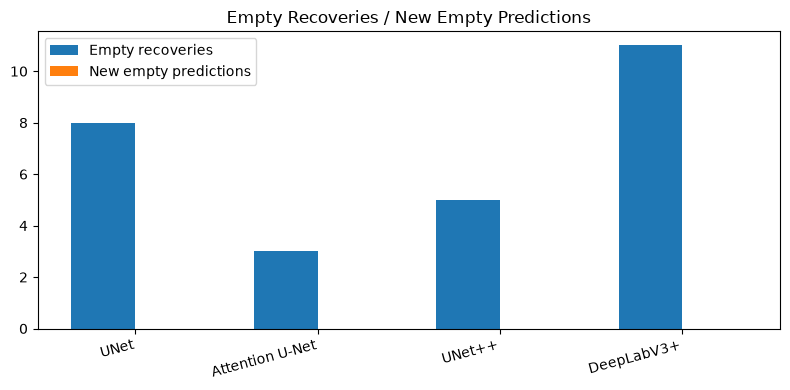

In [14]:

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(sum_df))
width = 0.35
ax.bar(x - width/2, sum_df["empty_recoveries"], width, label="Empty recoveries")
ax.bar(x + width/2, sum_df["new_empty_predictions"], width, label="New empty predictions")
ax.set_xticks(x)
ax.set_xticklabels(sum_df["model_display"], rotation=15, ha="right")
ax.set_title("Empty Recoveries / New Empty Predictions")
ax.legend()
plt.tight_layout()
plt.show()


## 21. Oracle-Benefit Retention

H2A_ORACLE_BENEFIT_RETENTION = (H2A_Dice - GLOBAL_Dice) / (ORACLE_Dice - GLOBAL_Dice)


In [15]:

print("Retention by model:")
for _, r in sum_df.iterrows():
    ret = r["H2A_ORACLE_BENEFIT_RETENTION"]
    print(f"  {r['model_display']:<18} {ret:.4f}" if ret is not None else f"  {r['model_display']:<18} N/A")


Retention by model:
  UNet               -2.1480
  Attention U-Net    -4.4367
  UNet++             -3.6845
  DeepLabV3+         -1.4272


## 22. Size-Stratified Results


In [16]:

comp_df = pd.read_csv(TABLES / "post_phase13_h2a_downstream_component_model_metrics.csv")
strat = comp_df.groupby(["size_stratum", "model"]).agg(
    n=("native_component_id", "count"),
    global_detected=("global_detected", "sum"),
    h2a_detected=("h2a_predicted_detected", "sum"),
    oracle_detected=("oracle_detected", "sum"),
    recoveries=("GLOBAL_TO_H2A_RECOVERY", "sum"),
    losses=("GLOBAL_TO_H2A_LOSS", "sum"),
).reset_index()
print(strat.to_string(index=False))


size_stratum          model  n  global_detected  h2a_detected  oracle_detected  recoveries  losses
       LARGE attention_unet 16               15            15               16           0       0
       LARGE  deeplabv3plus 16               14            15               16           1       0
       LARGE           unet 16               14            15               16           1       0
       LARGE         unetpp 16               14            15               16           1       0
      MEDIUM attention_unet 36               32            35               36           3       0
      MEDIUM  deeplabv3plus 36               30            34               36           4       0
      MEDIUM           unet 36               32            34               36           2       0
      MEDIUM         unetpp 36               31            36               36           5       0
       SMALL attention_unet 28               24            26               28           2       0
       SMA

## 23. Frozen Hard-Tiny Cohort

15 components. Preserved from Phase13.


In [17]:

ht = comp_df[comp_df["hard_tiny"]].groupby("model").agg(
    n=("native_component_id", "count"),
    global_detected=("global_detected", "sum"),
    h2a_detected=("h2a_predicted_detected", "sum"),
    oracle_detected=("oracle_detected", "sum"),
    recoveries=("GLOBAL_TO_H2A_RECOVERY", "sum"),
    losses=("GLOBAL_TO_H2A_LOSS", "sum"),
)
print(ht)


                 n  global_detected  h2a_detected  oracle_detected  \
model                                                                
attention_unet  15                3             7               14   
deeplabv3plus   15                2             5               15   
unet            15                0             6               14   
unetpp          15                0             5               14   

                recoveries  losses  
model                               
attention_unet           4       0  
deeplabv3plus            3       0  
unet                     6       0  
unetpp                   5       0  


## 24. Frozen Global-Empty Cohort

5 IMAGES from the frozen Phase13 global-empty cohort. Preserved from Phase13.

Those 5 frozen images contain **8 native components**. Where a component-level
table reports `n = 8`, that count is explicitly labelled
**`GLOBAL_EMPTY_COMPONENTS_WITHIN_5_FROZEN_IMAGES`** — it is a component count
within 5 frozen images, and is **never** to be reported as "8 global-empty images".


In [18]:

ge = comp_df[comp_df["global_empty_image"]].groupby("model").agg(
    n=("native_component_id", "count"),
    global_detected=("global_detected", "sum"),
    h2a_detected=("h2a_predicted_detected", "sum"),
    oracle_detected=("oracle_detected", "sum"),
    recoveries=("GLOBAL_TO_H2A_RECOVERY", "sum"),
    losses=("GLOBAL_TO_H2A_LOSS", "sum"),
)
print("GLOBAL_EMPTY_COMPONENTS_WITHIN_5_FROZEN_IMAGES")
print(ge)
_frozen_ge_images = int(comp_df.loc[comp_df["global_empty_image"], "sample_id"].nunique())
print(f"frozen global-empty IMAGES: {_frozen_ge_images} | components within them (per model): {int(ge['n'].iloc[0])}")
assert _frozen_ge_images == 5, f"frozen global-empty images {_frozen_ge_images} != 5"


GLOBAL_EMPTY_COMPONENTS_WITHIN_5_FROZEN_IMAGES
                n  global_detected  h2a_detected  oracle_detected  recoveries  \
model                                                                           
attention_unet  8                1             4                8           3   
deeplabv3plus   8                2             3                8           1   
unet            8                0             3                8           3   
unetpp          8                0             3                8           3   

                losses  
model                   
attention_unet       0  
deeplabv3plus        0  
unet                 0  
unetpp               0  
frozen global-empty IMAGES: 5 | components within them (per model): 8


## 25. Multi-Component Cohort


In [19]:

mc = comp_df[comp_df["multi_component_image"]].groupby("model").agg(
    n=("native_component_id", "count"),
    global_detected=("global_detected", "sum"),
    h2a_detected=("h2a_predicted_detected", "sum"),
    oracle_detected=("oracle_detected", "sum"),
    recoveries=("GLOBAL_TO_H2A_RECOVERY", "sum"),
    losses=("GLOBAL_TO_H2A_LOSS", "sum"),
)
print(mc)


                 n  global_detected  h2a_detected  oracle_detected  \
model                                                                
attention_unet  98               78            89               97   
deeplabv3plus   98               71            84               98   
unet            98               76            88               97   
unetpp          98               77            89               97   

                recoveries  losses  
model                               
attention_unet          11       0  
deeplabv3plus           14       1  
unet                    12       0  
unetpp                  12       0  


## 26. Cross-Architecture Consistency


In [20]:

cross = pd.read_csv(TABLES / "post_phase13_h2a_downstream_cross_architecture_summary.csv")
print(cross.to_string(index=False))


                                    Unnamed: 0  value
             cases_h2a_improved_vs_global_all4      3
             cases_h2a_nonworse_vs_global_all4      3
                cases_h2a_worse_vs_global_all4     83
            cases_h2a_improved_vs_phase13_all4     37
               cases_h2a_worse_vs_phase13_all4     38
components_recovered_vs_global_by_at_least_one     29
        components_recovered_vs_global_by_all4      5
     components_lost_vs_global_by_at_least_one      1
             components_lost_vs_global_by_all4      0


## 27. Localizer-to-Downstream Translation


In [21]:

link = pd.read_csv(TABLES / "post_phase13_h2a_localizer_to_downstream_comparison.csv")
print(link.to_string(index=False))


         model   model_display  h2a_proposal_count  h2a_pixel_any_hit_precision  h2a_bbox_any_hit_precision  h2a_tiny90  h2a_overall90  h2a_overall50  h2a_any_overlap  h2a_mean_coverage  h2a_mean_union_area  h2a_score_max  h2a_score_iqr  h2a_fraction_at_max  h2a_macro_dice  h2a_macro_precision  h2a_macro_recall  h2a_mean_fp  h2a_mean_fn  h2a_component_recoveries_vs_global  h2a_component_losses_vs_global  phase13_proposal_count  phase13_pixel_any_hit_precision  phase13_tiny90  phase13_overall90  phase13_macro_dice  phase13_macro_precision  phase13_macro_recall  phase13_mean_fp  phase13_mean_fn
          unet            UNet                 457                     0.275711                    0.273523    0.694444       0.638158       0.822368            0.875           0.787897             0.004795       0.141637       0.001654             0.645514        0.313779             0.245046          0.686679  8344.252427  2381.330097                                  17                          

## 28. Limitations

1. H2A is a single-seed adaptive VAL-development experiment.
2. The deployment-balanced selection rule structurally cannot discriminate epochs 1-30 (proposals appear only from epoch 31).
3. No direct model-tensor cross-check at epochs 31/53/68 (snapshots not retained).
4. Descriptive comparison only — no statistical superiority claim.
5. No threshold search or proposal grid was run.
6. TEST remains untouched; these are development-data results only.


## 29. Adaptive-Development Disclosure

H2A is an adaptive VAL-development revision initiated after Phase 13 `REVISE_LOCALIZER` and H1 acceptance-only insufficiency.

- The H2A checkpoint-selection rule was frozen BEFORE H2A-B1 training.
- The downstream protocol was frozen BEFORE H2A-B2 segmentation execution.
- VAL remains development data.
- No H2A result substitutes for final TEST evaluation.
- TEST remains untouched.


## 30. Explicit Adjudication Stop Boundary

**H2A-B2 DOES NOT adjudicate H2A.**

The execution returns evidence only. H2A outcome adjudication is a separate supervisor step.

The following are NOT authorized and NOT performed:
- R1 selective acceptance
- Loss / target / sigma redesign
- Architecture redesign
- H2B / H3
- Phase14
- TEST access


## 30b. Mandatory Complete Tables (Untruncated)

These tables are rendered **in full** — no `head()`, no `tail()`, no notebook ellipsis.
Source: the immutable on-disk artifacts written by the H2A-B2 execution.

- Model summary: 4 / 4 rows
- Case-model metrics: 412 / 412 rows (103 cases x 4 models)
- Component-model metrics: 608 / 608 rows (152 components x 4 models)


In [22]:

import pandas as _pd
_pd.set_option("display.max_rows", None)
_pd.set_option("display.max_columns", None)
_pd.set_option("display.width", 0)
_pd.set_option("display.max_colwidth", None)

# --- 4 / 4 model summary rows ------------------------------------------------
_ms = pd.read_csv(TABLES / "post_phase13_h2a_downstream_model_summary.csv")
print("=" * 100)
print(f"MODEL SUMMARY — {len(_ms)} / 4 rows")
print("=" * 100)
print(_ms.to_string(index=False))
print()
assert len(_ms) == 4, f"model summary rows {len(_ms)} != 4"


MODEL SUMMARY — 4 / 4 rows
         model   model_display  proposal_count  mean_proposals_per_image  mean_intervention_union_area  global_macro_dice  phase13_predicted_macro_dice  h2a_predicted_macro_dice  oracle_macro_dice  DELTA_H2A_GLOBAL_DICE  DELTA_H2A_PHASE13_DICE  ORACLE_GAIN_FROM_GLOBAL  H2A_ORACLE_BENEFIT_RETENTION  H2A_ORACLE_GAP  global_macro_iou  phase13_predicted_macro_iou  h2a_predicted_macro_iou  oracle_macro_iou  global_macro_precision  phase13_predicted_macro_precision  h2a_predicted_macro_precision  oracle_macro_precision  global_macro_recall  phase13_predicted_macro_recall  h2a_predicted_macro_recall  oracle_macro_recall  mean_global_fp  mean_phase13_fp  mean_h2a_fp  mean_oracle_fp  mean_global_fn  mean_phase13_fn  mean_h2a_fn  mean_oracle_fn  fp_delta_vs_global  fp_delta_vs_phase13  fn_delta_vs_global  fn_delta_vs_phase13  cases_improved_vs_global  cases_same_vs_global  cases_worse_vs_global  cases_improved_vs_phase13  cases_same_vs_phase13  cases_worse_vs_phase13  

In [23]:

# --- 412 / 412 case-model rows ----------------------------------------------
_cm = pd.read_csv(TABLES / "post_phase13_h2a_downstream_case_model_metrics.csv")
print("=" * 100)
print(f"CASE-MODEL METRICS — {len(_cm)} / 412 rows (103 cases x 4 models)")
print("=" * 100)
print(_cm.to_string(index=False))
print()
assert len(_cm) == 412, f"case-model rows {len(_cm)} != 412"
assert _cm["sample_id"].nunique() == 103, f"case-model cases {_cm['sample_id'].nunique()} != 103"
assert _cm["model"].nunique() == 4, f"case-model models {_cm['model'].nunique()} != 4"
print(f"CONFIRMED: {len(_cm)} rows | {_cm['sample_id'].nunique()} cases | {_cm['model'].nunique()} models")


CASE-MODEL METRICS — 412 / 412 rows (103 cases x 4 models)
                       sample_id          model   model_display  native_height  native_width  native_gt_components  h2a_proposal_count  h2a_proposal_union_area_fraction  hard_tiny_image  global_empty_image  multi_component_image  h2a_proposal_score_mean  h2a_proposal_score_max  global_dice   global_iou  global_precision  global_recall  global_tp_pixels  global_fp_pixels  global_fn_pixels  global_prediction_empty  global_hd95  global_hd95_valid global_hd95_invalid_reason  global_detected_native_components  global_missed_native_components  global_object_recall  oracle_dice  oracle_iou  oracle_precision  oracle_recall  oracle_tp_pixels  oracle_fp_pixels  oracle_fn_pixels  oracle_prediction_empty  oracle_hd95  oracle_hd95_valid  oracle_hd95_invalid_reason  oracle_detected_native_components  oracle_missed_native_components  oracle_object_recall  phase13_predicted_dice  phase13_predicted_iou  phase13_predicted_precision  phase13_pred

In [24]:

# --- 608 / 608 component-model rows -----------------------------------------
_km = pd.read_csv(TABLES / "post_phase13_h2a_downstream_component_model_metrics.csv")
print("=" * 100)
print(f"COMPONENT-MODEL METRICS — {len(_km)} / 608 rows (152 components x 4 models)")
print("=" * 100)
print(_km.to_string(index=False))
print()
assert len(_km) == 608, f"component-model rows {len(_km)} != 608"
assert _km["native_component_id"].notna().sum() == 608
print(f"CONFIRMED: {len(_km)} rows | {_km['model'].nunique()} models | "
      f"{_km.groupby('model')['native_component_id'].count().to_dict()}")


COMPONENT-MODEL METRICS — 608 / 608 rows (152 components x 4 models)
                       sample_id  native_component_id          model   model_display size_stratum  component_pixels  hard_tiny  global_empty_image  multi_component_image  h2a_coverage_fraction  h2a_covered90  h2a_covered50  h2a_any_overlap  global_detected  oracle_detected  phase13_predicted_detected  h2a_predicted_detected  GLOBAL_TO_H2A_RECOVERY  GLOBAL_TO_H2A_LOSS  PHASE13_TO_H2A_RECOVERY  PHASE13_TO_H2A_LOSS
66b947d8ead11ae1260bc3142ca1707d                    1           unet            UNet         TINY               522      False               False                  False               0.967742           True           True             True            False             True                        True                    True                    True               False                    False                False
66b947d8ead11ae1260bc3142ca1707d                    1 attention_unet Attention U-Net         TINY  

## 31. Artifact SHA Registry


In [25]:

artifacts = [
    str(ROOT / "reports/audits/post_phase13_h2a_protocol_frozen.json"),
    str(ROOT / "reports/audits/post_phase13_h2a_training_evaluation.json"),
    str(ROOT / "reports/audits/post_phase13_h2a_training_trajectory_reproduction.json"),
    str(ROOT / "reports/audits/post_phase13_h2a_selection_replay_verification.json"),
    str(ROOT / "reports/audits/post_phase13_h2a_b1_checkpoint_crosscheck_limitation.json"),
    str(ROOT / "reports/audits/post_phase13_h2a_downstream_integrity.json"),
    str(ROOT / "reports/audits/post_phase13_h2a_best_checkpoint_standalone_evaluation.json"),
    str(ROOT / "reports/tables/post_phase13_h2a_best_checkpoint_case_proposals.csv"),
    str(ROOT / "reports/tables/post_phase13_h2a_best_checkpoint_proposals.csv"),
    str(ROOT / "reports/tables/post_phase13_h2a_best_checkpoint_component_coverage.csv"),
    str(ROOT / "reports/tables/post_phase13_h2a_best_checkpoint_size_stratified.csv"),
    str(ROOT / "reports/tables/post_phase13_h2a_downstream_case_model_metrics.csv"),
    str(ROOT / "reports/tables/post_phase13_h2a_downstream_component_model_metrics.csv"),
    str(ROOT / "reports/tables/post_phase13_h2a_downstream_model_summary.csv"),
    str(ROOT / "reports/tables/post_phase13_h2a_downstream_cross_architecture_summary.csv"),
    str(ROOT / "reports/tables/post_phase13_h2a_localizer_to_downstream_comparison.csv"),
    str(ROOT / "reports/tables/post_phase13_h2a_vs_phase13_localizer_comparison.csv"),
]
for a in artifacts:
    p = Path(a)
    print(f"{sha(p)}  {p.name}")


0fafc793b3a814e010e1fdd48f6a2333042985eaef4a44e0382b3991800da96b  post_phase13_h2a_protocol_frozen.json
7ecd3a04fd6bfa6051afa3bd4536566d61a81287c73f34fb2e4689d0e0587899  post_phase13_h2a_training_evaluation.json
4be050b0eb72106360bcd07832f1bfe57b31ad1c3dfe7eb6cf095ec24e24ddbf  post_phase13_h2a_training_trajectory_reproduction.json
72fd6494a7256d7624a3c84773f4cf3ab6977fa53be0699b8cbc111cb3af5c0f  post_phase13_h2a_selection_replay_verification.json
1ec2d7cc63c97a89c47c63ca6cdaae3382a19c97d3ce34a73c1ceb61d0582a7b  post_phase13_h2a_b1_checkpoint_crosscheck_limitation.json
0c3b1175b9dd425e57ebb3770d6d37ee16be71e06fb42d24edf6ea46b8a7fec3  post_phase13_h2a_downstream_integrity.json
d4a044c0c5e0f4dee4ed121bedb9b9421fb848ad138e2bbdc5f249a4d7cb33bd  post_phase13_h2a_best_checkpoint_standalone_evaluation.json
93ebebf4ede237e408a7398bfe86620e28054950831595c3a24f7d1e0fe6ef9f  post_phase13_h2a_best_checkpoint_case_proposals.csv
4004e5b0b38bec11b9f63934be8efea253f20339952ac57ebf5e0b70e47e454f  post_p